<a href="https://colab.research.google.com/github/sandesh0shinde/student-performance-prediction/blob/main/Student_Performance_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Student Performance Prediction Using Machine Learning

## 1. Introduction

Machine Learning is a branch of Artificial Intelligence that allows computers to learn patterns from data and make predictions.

In this project, I will build a Machine Learning model to estimate students' final mathematics grades using information such as study time, absences, and previous academic performance indicators.

The project uses Python and Google Colab for data analysis, model training, visualization, and evaluation.

## 2. Project Objectives

- To understand the basics of Machine Learning.
- To load and explore a real-world student dataset.
- To clean and prepare data for model training.
- To train a Linear Regression model.
- To evaluate predictions using suitable performance metrics.
- To visualize the results and document the findings.

## 3. Tools and Technologies

- **Programming language:** Python
- **Platform:** Google Colab
- **Libraries:** Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn
- **Machine Learning type:** Supervised Learning
- **Problem type:** Regression

## 4. Project Workflow

1. Load the dataset.
2. Explore and visualize the data.
3. Select input features and the target variable.
4. Split the data into training and testing sets.
5. Train the Machine Learning model.
6. Evaluate the model.
7. Visualize predictions and write the conclusion.

## 5. Import the Required Libraries

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 6. Dataset Collection

For this project, I will use the Student Performance dataset from the UCI Machine Learning Repository.

The dataset contains information about students, including study time, absences, previous grades, and other school-related factors.

The Mathematics dataset will be used for this project. The target variable is `G3`, which represents the student's final mathematics grade on a scale from 0 to 20.

The dataset will be downloaded and loaded into a Pandas DataFrame for further analysis.

**Dataset source:** [UCI Student Performance Dataset](https://archive.ics.uci.edu/dataset/320/student+performance)

In this project, I am using the dataset by downloading it locally for an easier approach to use.

In [50]:
df = pd.read_csv("/content/sample_data/student-mat.csv", sep=";")
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


## 7. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is the process of examining data before training a Machine Learning model.

In this section, I will check the dataset's structure, column names, statistical summary, missing values, and duplicate records.

This helps me understand the available information and identify potential data-quality issues before model training.

In [51]:
#DataFrame Summary
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [52]:
#column information
print("Column Names: ")
print(df.columns.to_list())

Column Names: 
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [53]:
#Statistical Summary
print(df.describe())

              age        Medu        Fedu  ...          G1          G2          G3
count  395.000000  395.000000  395.000000  ...  395.000000  395.000000  395.000000
mean    16.696203    2.749367    2.521519  ...   10.908861   10.713924   10.415190
std      1.276043    1.094735    1.088201  ...    3.319195    3.761505    4.581443
min     15.000000    0.000000    0.000000  ...    3.000000    0.000000    0.000000
25%     16.000000    2.000000    2.000000  ...    8.000000    9.000000    8.000000
50%     17.000000    3.000000    2.000000  ...   11.000000   11.000000   11.000000
75%     18.000000    4.000000    3.000000  ...   13.000000   13.000000   14.000000
max     22.000000    4.000000    4.000000  ...   19.000000   19.000000   20.000000

[8 rows x 16 columns]


In [54]:
#Check Missing Values
print(df.isnull().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [55]:
#Check Duplicate Records
print(df.duplicated().sum())

0


## 8. Data Visualization

Data visualization helps us understand patterns and distributions in a dataset through charts.

### 8.1 Distribution of Final Grades

This histogram shows how frequently different final mathematics grades occur among students.

The chart helps identify common grade ranges and understand the distribution of the target variable `G3`.

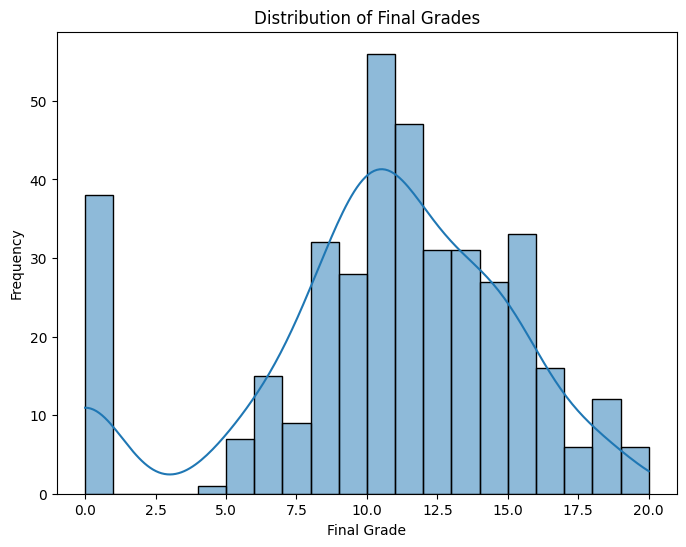

In [56]:
plt.figure(figsize=(8,6))
sns.histplot(df['G3'], bins=20, kde=True)
plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade")
plt.ylabel("Frequency")
plt.show()

### 8.2 Study Time and Final Grades

This box plot compares students' final grades across different weekly study-time categories.

It helps us explore whether grade distributions differ among students who report different amounts of study time. The chart shows an association in the dataset and does not establish that study time alone causes a particular grade.

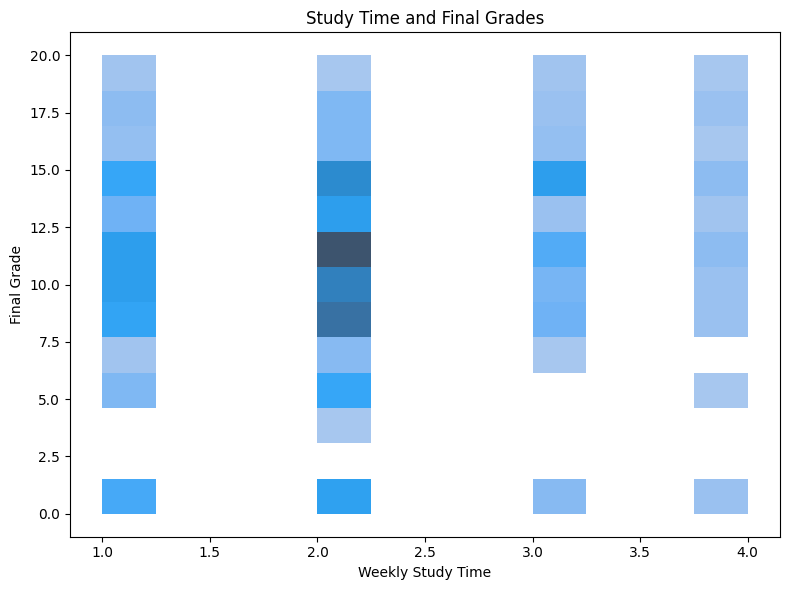

In [57]:
plt.figure(figsize=(8,6))
sns.histplot(data=df, x='studytime', y='G3')
plt.title("Study Time and Final Grades")
plt.xlabel("Weekly Study Time")
plt.ylabel("Final Grade")
plt.tight_layout()
plt.show()

## 9. Feature Selection

Feature selection means choosing the columns that will help our model predict students' final exam marks.

In this project, we use information such as age, study time, family background, and absences to predict the final grade (G3).

We will not use G1 and G2 in our first model because they contain students' previous grades. This helps us check how well the model can predict final marks without using previous exam marks.

In [58]:
X = df.drop(columns=['G1', 'G2', 'G3'])

#Target Column/Feature
y = df['G3']

print("Input features:", X.shape)
print("Target values:", y.shape)

X.head()

Input features: (395, 30)
Target values: (395,)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4


In [59]:
y.head()

,G3
0,6
1,6
2,10
3,15
4,10


- X contains the information used to make predictions.
- y contains the final grades we want to predict.
- G1 and G2 are excluded from the input.
- G3 is the final grade and is our target.

### Data Preprocessing
Finding the numerical and categorical columns.
Since, linear regression uses numerical values to predict the target value, we must convert the categorical values(string) in the dataset to numerical values(float or int)

In [60]:
#Seperating Numerical and Categorical Data Columns
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(exclude=['object']).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

Categorical columns: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Numerical columns: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']


In [61]:
#converting Categorical Data to Numerical Data
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True, dtype=int)
X.head()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,school_MS,sex_M,address_U,famsize_LE3,Pstatus_T,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,1,3,6,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,1,1,0,0
1,17,1,1,1,2,0,5,3,3,1,1,3,4,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0
2,15,1,1,1,2,3,4,3,2,2,3,3,10,0,0,1,1,1,0,0,0,0,0,1,0,0,0,1,0,1,0,1,0,1,0,1,1,1,0
3,15,4,2,1,3,0,3,2,2,1,1,5,2,0,0,1,0,1,1,0,0,0,0,0,1,0,1,0,0,1,0,0,1,1,1,1,1,1,1
4,16,3,3,1,2,0,4,3,2,1,2,5,4,0,0,1,0,1,0,1,0,0,0,1,0,0,1,0,0,0,0,0,1,1,0,1,1,0,0


In [62]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 276
Testing rows: 119


## 10. Model Training

Model training is the process of teaching a machine learning model using data.

First, we divide the dataset into training data and testing data. The training data teaches the model, while the testing data checks how well it predicts new results.

In this project, we use Linear Regression to predict students' final exam marks.

Let's starting with preparing the Training and Testing Data

In [63]:
# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

## 11. Model Evaluation

Model evaluation helps us understand how accurately our model predicts students' final grades.

We use MAE, RMSE, and R-squared (R²) to measure the model's performance. These values help us understand the difference between actual grades and predicted grades.

In [64]:
#Predicting Final Grades
y_pred = model.predict(X_test)

In [65]:
#Calculate Evaluation Metrics

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)
print("R-squared (R²):", r2)

Mean Absolute Error (MAE): 3.2881398680758953
Root Mean Squared Error (RMSE): 4.217846027981648
R-squared (R²): 0.19069357680255783


Understanding the results:
- MAE: The average absolute difference between actual and predicted grades. Lower is generally better.
- RMSE: Measures prediction errors and gives more weight to larger errors. Lower is generally better.
- R² Score: Shows how well the model explains differences in grades. A score closer to 1 generally indicates a better fit.

### Model Improvement Using Random Forest

In this step, I use the Random Forest Regressor algorithm to improve the prediction of students' final mathematics grades.

Random Forest combines multiple decision trees to make predictions. It can learn complex relationships between student information and final grades.

I will compare its performance with the Linear Regression model using MAE, RMSE, and R-squared score.

In [66]:
#Creating Random Forest Model
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=2,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_y_pred = rf_model.predict(X_test)

In [67]:
rf_mae = mean_absolute_error(y_test, rf_y_pred)
rf_rmse = mean_squared_error(y_test, rf_y_pred) ** 0.5
rf_r2 = r2_score(y_test, rf_y_pred)

print("Random Forest Model Performance")
print("Mean Absolute Error (MAE):", rf_mae)
print("Root Mean Squared Error (RMSE):", rf_rmse)
print("R-squared (R²):", rf_r2)

Random Forest Model Performance
Mean Absolute Error (MAE): 3.187536531157477
Root Mean Squared Error (RMSE): 4.0057113069952095
R-squared (R²): 0.2700538264728384


### Hyperparameter Tuning

Hyperparameter tuning means trying different model settings to find a suitable configuration.

In this project, I test different Random Forest settings and compare their performance. The aim is to reduce prediction errors and improve the R-squared score.

In [68]:
#Try different model settings
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators' : [100, 200, 300],
    'max_depth' : [5, 10, 15],
    'min_samples_leaf' : [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator = RandomForestRegressor(random_state=42),
    param_grid = param_grid,
    cv = 5,
    n_jobs = -1,
    verbose = 1,
    scoring = 'neg_mean_squared_error'
)

grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
print("Best Parameters:", best_params)

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 200}


In [48]:

best_model = grid_search.best_estimator_

tuned_pred = best_model.predict(X_test)

tuned_mae = mean_absolute_error(y_test, tuned_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_pred))
tuned_r2 = r2_score(y_test, tuned_pred)

print("Tuned Random Forest Results")
print("---------------------------")
print("MAE:", round(tuned_mae, 3))
print("RMSE:", round(tuned_rmse, 3))
print("R-squared:", round(tuned_r2, 3))


Tuned Random Forest Results
---------------------------
MAE: 3.091
RMSE: 3.918
R-squared: 0.302


The tuned model now explains about **30.2%** of the variation in final grades on the test set. Its average absolute prediction error is about 3.09 grade points.

This is an improvement, although the model still has limited predictive power.

## Final Model Results

After comparing Linear Regression and Random Forest, I used hyperparameter tuning to improve the Random Forest model.

The tuned Random Forest model achieved a Mean Absolute Error (MAE) of **3.091**, a Root Mean Squared Error (RMSE) of **3.918**, and an R-squared score of **0.302**.

Compared with the initial Linear Regression model, the tuned Random Forest model produced lower prediction errors and a higher R-squared score. However, its predictions are still limited, and further improvements may be possible.

This comparison helped me understand the importance of selecting suitable algorithms and tuning their settings in Machine Learning.

## Visualization of Predictions

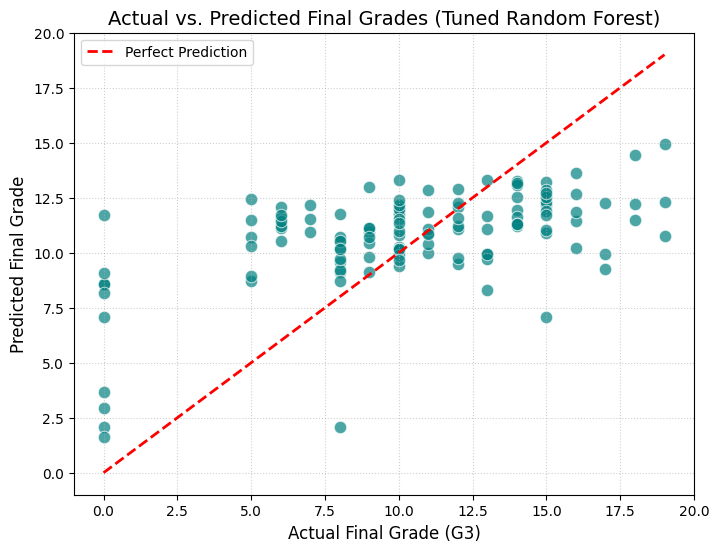

In [70]:
plt.figure(figsize=(8, 6))
# Scatter plot of actual vs predicted values
sns.scatterplot(x=y_test, y=tuned_pred, alpha=0.7, color='teal', edgecolor='w', s=80)

# Ideal 1:1 prediction line
max_val = max(max(y_test), max(tuned_pred))
min_val = min(min(y_test), min(tuned_pred))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=2, label='Perfect Prediction')

plt.title("Actual vs. Predicted Final Grades (Tuned Random Forest)", fontsize=14)
plt.xlabel("Actual Final Grade (G3)", fontsize=12)
plt.ylabel("Predicted Final Grade", fontsize=12)
plt.xlim(min_val - 1, max_val + 1)
plt.ylim(min_val - 1, max_val + 1)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()